# Gradient boosting

Import relevant libraries.


In [3]:
#@title Run this first: course helper module (ai4_tools). Double-click to see the code.
# ENG4200 / ENG5338 helper module. Source of truth is notebooks/ai4_tools.py in the
# course repository. Do not edit here: edit there and rerun build_toolcell.py, or the
# change is lost the next time the notebook is reissued.
_AI4_TOOLS_SOURCE = r'''
"""
ai4_tools: runtime reporting and cost measurement for ENG4200 / ENG5338.

Why this exists. The courseworks ask for computational efficiency: training time,
inference latency and memory footprint. A number timed on one runtime and compared
against a number timed on another is not evidence, so every timing this module produces
carries the runtime it was measured on.

Use it like this:

    show_runtime()                       # once, at the top of every notebook
    r = benchmark(model, Xtr, ytr, Xte, yte)
    table = ResultsTable(); table.add("logistic regression", r); table.df()
    decision("Stratified 5-fold", "3.4% positives, plain k-fold can empty a fold", r)

Standard library plus numpy only. pandas, scikit-learn, torch and psutil are all optional
and are used if present. Written for Python 3.8 and later so it runs on Colab, on the lab
machines and on a student laptop without changes.
"""

import gc
import importlib.util
import os
import platform
import statistics
import subprocess
import sys
import threading
import time
import tracemalloc
from contextlib import contextmanager

__all__ = [
    "runtime_info", "runtime_line", "show_runtime",
    "timed", "benchmark", "peak_memory",
    "ResultsTable", "decision",
    "register_sections", "check", "check_raises", "scorecard", "reset_checks",
]

_MB = 1024.0 * 1024.0


# ----------------------------------------------------------------------------------
# Runtime description
# ----------------------------------------------------------------------------------

def _have(name):
    """True if a module is importable, without importing it."""
    try:
        return importlib.util.find_spec(name) is not None
    except (ImportError, ValueError):
        return False


def _cpu_model():
    system = platform.system()
    try:
        if system == "Linux":
            with open("/proc/cpuinfo") as fh:
                for line in fh:
                    if line.startswith("model name"):
                        return line.split(":", 1)[1].strip()
        elif system == "Darwin":
            out = subprocess.check_output(
                ["sysctl", "-n", "machdep.cpu.brand_string"],
                stderr=subprocess.DEVNULL, timeout=5,
            )
            return out.decode().strip()
    except Exception:
        pass
    return platform.processor() or platform.machine() or "unknown CPU"


def _total_ram_gb():
    try:
        import psutil  # noqa: F401
        return psutil.virtual_memory().total / (1024 ** 3)
    except Exception:
        pass
    try:
        return (os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")) / (1024 ** 3)
    except (ValueError, OSError, AttributeError):
        return None


def _gpu_state():
    """(has_gpu, name). Reports what torch can actually use, not what is installed."""
    if "torch" not in sys.modules and not _have("torch"):
        return False, "torch not installed"
    try:
        import torch
        if torch.cuda.is_available():
            return True, torch.cuda.get_device_name(0)
        if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
            return True, "Apple MPS"
        return False, "none attached"
    except Exception as exc:
        return False, "torch present but unusable ({})".format(type(exc).__name__)


def runtime_info():
    """Everything that makes one timing comparable with another, as a dict."""
    has_gpu, gpu_name = _gpu_state()
    ram = _total_ram_gb()
    return {
        "platform": "Google Colab" if _have("google.colab") else platform.system(),
        "python": platform.python_version(),
        "cpu": _cpu_model(),
        "cores": os.cpu_count(),
        "ram_gb": round(ram, 1) if ram else None,
        "accelerator": gpu_name if has_gpu else "CPU only",
        "has_gpu": has_gpu,
    }


def runtime_line(info=None):
    """The one line that goes with every number you report. Paste it into the report."""
    i = info or runtime_info()
    ram = "{} GB".format(i["ram_gb"]) if i["ram_gb"] else "RAM unknown"
    return "{} | {} ({} cores, {}) | {} | Python {}".format(
        i["platform"], i["cpu"], i["cores"], ram, i["accelerator"], i["python"]
    )


def show_runtime():
    """Run this once at the top of every notebook. Returns the line so you can keep it."""
    info = runtime_info()
    line = runtime_line(info)
    print("Runtime:", line)
    if info["has_gpu"] and info["platform"] == "Google Colab":
        print(
            "\nA GPU is attached. scikit-learn cannot use it, so for Tutorials 1 to 4 it\n"
            "buys you nothing and spends a rationed allowance you will want in November\n"
            "for Lab 2 and CW3. Set Runtime > Change runtime type > CPU unless you are\n"
            "running PyTorch."
        )
    elif info["has_gpu"]:
        print("\nAn accelerator is available. scikit-learn will not use it; only PyTorch will.")
    return line


# ----------------------------------------------------------------------------------
# Timing
# ----------------------------------------------------------------------------------

@contextmanager
def timed(label="elapsed", quiet=False):
    """with timed('fit'): model.fit(X, y)   ->   seconds land in .seconds"""
    class _T:
        seconds = None
    t = _T()
    start = time.perf_counter()
    try:
        yield t
    finally:
        t.seconds = time.perf_counter() - start
        if not quiet:
            print("{}: {:.4f} s".format(label, t.seconds))


def _clone(model):
    try:
        from sklearn.base import clone
        return clone(model)
    except Exception:
        import copy
        return copy.deepcopy(model)


def _median_of(fn, repeats):
    """One warm-up run that is thrown away, then `repeats` timed runs. Median, not mean:
    a single slow run caused by something else on the machine should not move the number."""
    fn()
    samples = []
    for _ in range(repeats):
        gc.collect()
        start = time.perf_counter()
        fn()
        samples.append(time.perf_counter() - start)
    return statistics.median(samples), min(samples)


def benchmark(model, X_train, y_train, X_test, y_test=None, scorer=None,
              repeats=3, label=None, measure_memory=False):
    """Fit and predict cost for one model, on one runtime, in a form you can tabulate.

    Returns a dict with fit_s, predict_s, predict_ms_per_1k and the runtime line.
    `predict_ms_per_1k` is the one CW3 asks for, because inference latency has to be
    per unit of work or it just measures how big your test set happened to be.

    Note the difference from %timeit, which is fine for a demonstration but prints to the
    screen instead of returning a value you can put in a results table.
    """
    n_train = len(X_train)
    n_test = len(X_test)

    fit_median, fit_best = _median_of(lambda: _clone(model).fit(X_train, y_train), repeats)

    fitted = _clone(model).fit(X_train, y_train)
    pred_median, pred_best = _median_of(lambda: fitted.predict(X_test), repeats)

    score = None
    if y_test is not None:
        try:
            score = scorer(y_test, fitted.predict(X_test)) if scorer else fitted.score(X_test, y_test)
        except Exception as exc:
            print("Could not score this model: {}".format(exc))

    result = {
        "model": label or type(model).__name__,
        "score": score,
        "fit_s": fit_median,
        "fit_s_best": fit_best,
        "predict_s": pred_median,
        "predict_ms_per_1k": (pred_median / n_test) * 1000.0 * 1000.0 if n_test else None,
        "n_train": n_train,
        "n_test": n_test,
        "repeats": repeats,
        "runtime": runtime_line(),
    }

    if measure_memory:
        mb, metric = peak_memory(lambda: _clone(model).fit(X_train, y_train))
        result["peak_mem_mb"] = mb
        result["mem_metric"] = metric

    return result


# ----------------------------------------------------------------------------------
# Memory
# ----------------------------------------------------------------------------------

def _rss_bytes():
    """Current resident set size of this process, or None if we cannot read it.

    Resident set size, not the Python heap. scikit-learn's trees and torch's tensors are
    allocated in C, which tracemalloc never sees, so a tracemalloc figure for a random
    forest comes out roughly two orders of magnitude too small.
    """
    try:
        import psutil
        return psutil.Process().memory_info().rss
    except Exception:
        pass
    try:
        with open("/proc/self/statm") as fh:
            return int(fh.read().split()[1]) * os.sysconf("SC_PAGE_SIZE")
    except Exception:
        return None


def peak_memory(fn, interval=0.01):
    """Peak memory used by fn(), as (megabytes, which_metric).

    The second value is not decoration. Three different quantities can come back here
    depending on the runtime, and they are not interchangeable:

      GPU device memory      measured by torch when a CUDA device is attached
      host process RSS       peak resident memory minus the baseline, sampled while fn runs
      host Python heap       tracemalloc, the last resort, and an undercount for anything
                             that allocates in C, which includes scikit-learn and torch

    A table that does not say which one it holds cannot be compared with anyone else's.
    So the metric travels with the number.
    """
    has_gpu, _ = _gpu_state()
    if has_gpu:
        try:
            import torch
            if torch.cuda.is_available():
                torch.cuda.synchronize()
                torch.cuda.reset_peak_memory_stats()
                fn()
                torch.cuda.synchronize()
                return torch.cuda.max_memory_allocated() / _MB, "GPU device memory (torch.cuda)"
        except Exception:
            pass

    gc.collect()
    baseline = _rss_bytes()
    if baseline is not None:
        peak = [baseline]
        stop = threading.Event()

        def _sample():
            while not stop.is_set():
                current = _rss_bytes()
                if current is not None and current > peak[0]:
                    peak[0] = current
                stop.wait(interval)

        watcher = threading.Thread(target=_sample, daemon=True)
        watcher.start()
        try:
            fn()
        finally:
            stop.set()
            watcher.join(timeout=1.0)
        return max(peak[0] - baseline, 0) / _MB, "host process RSS (peak minus baseline)"

    gc.collect()
    tracemalloc.start()
    try:
        fn()
        _, peak_traced = tracemalloc.get_traced_memory()
    finally:
        tracemalloc.stop()
    return peak_traced / _MB, "host Python heap (tracemalloc, undercounts C allocations)"


# ----------------------------------------------------------------------------------
# Results table and decision log
# ----------------------------------------------------------------------------------

class ResultsTable:
    """Accumulates benchmark() rows. Every row keeps the runtime it was measured on, so
    a table assembled across two sessions cannot silently mix a CPU run with a GPU one."""

    def __init__(self):
        self.rows = []

    def add(self, label, result=None, **extra):
        if result is None:
            result = {}
        row = dict(result)
        row["model"] = label
        row.update(extra)
        self.rows.append(row)
        return self

    def df(self, columns=("model", "score", "fit_s", "predict_ms_per_1k")):
        try:
            import pandas as pd
        except ImportError:
            return self.rows
        frame = pd.DataFrame(self.rows)
        keep = [c for c in columns if c in frame.columns]
        rest = [c for c in frame.columns if c not in keep and c != "runtime"]
        return frame[keep + rest]

    def runtimes(self):
        """The distinct runtimes in this table. More than one means the timings in it
        are not comparable with each other, and the table needs splitting or rerunning."""
        return sorted({r.get("runtime") for r in self.rows if r.get("runtime")})

    def check(self):
        seen = self.runtimes()
        if len(seen) > 1:
            print("Warning: this table mixes {} different runtimes. The scores are still\n"
                  "valid but the timings are not comparable across rows:".format(len(seen)))
            for s in seen:
                print("  -", s)
            return False
        return True


_SECTIONS = {}
_CHECKS = []


def register_sections(titles):
    """register_sections({1: "Python basics", 2: "NumPy"}) so the scorecard can name them."""
    _SECTIONS.clear()
    _SECTIONS.update(titles)


def reset_checks():
    del _CHECKS[:]


def _section_of(label):
    head = str(label).split(None, 1)[0]
    try:
        return int(head.split(".")[0])
    except (ValueError, IndexError):
        return 0


def check(label, condition, hint=None):
    """Assertion with a hint instead of a traceback.

    An AssertionError on its own tells you nothing useful, so a failed check says what
    was expected and what to try, and the notebook keeps running so the later exercises
    are still attemptable.

        check("2.1 shape is 3 by 4", a.shape == (3, 4), "np.reshape takes the new shape")

    `condition` is normally a boolean, which means Python evaluates it before check() ever
    sees it: if the expression itself raises, the student gets their own traceback at the
    call site, which is the right thing to happen. The bool() is still guarded because
    comparing two numpy arrays gives an array, and calling bool() on it raises rather than
    returning False.

    Pass a zero-argument callable instead when the expression is expected to raise and you
    want the failure recorded rather than thrown:

        check("3.4 raises on a bad column", lambda: df["nope"], "KeyError is correct here")
    """
    if callable(condition):
        try:
            condition = condition()
        except Exception as exc:
            _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": False})
            print("FAIL  {}".format(label))
            print("      raised {}: {}".format(type(exc).__name__, exc))
            if hint:
                print("      hint: {}".format(hint))
            return False
    try:
        passed = bool(condition)
    except Exception as exc:
        passed = False
        hint = "{} (comparison gave {}, not a single True or False)".format(
            hint or "", type(exc).__name__).strip()

    _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": passed})
    if passed:
        print("PASS  {}".format(label))
    else:
        print("FAIL  {}".format(label))
        if hint:
            print("      hint: {}".format(hint))
    return passed


def check_raises(label, fn, expected=Exception, hint=None):
    """Passes when fn() raises `expected`. For demonstrating what going wrong looks like.

    Without this, a notebook that wants to show a student a KeyError has to contain a
    check that fails on purpose, which then sits on their scorecard telling them to redo a
    section they got right.

        check_raises("4.3 missing column", lambda: df["nope"], KeyError)
    """
    try:
        fn()
    except expected as exc:
        _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": True})
        print("PASS  {}  (raised {} as expected: {})".format(label, type(exc).__name__, exc))
        return True
    except Exception as exc:
        _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": False})
        print("FAIL  {}  (raised {}, expected {})".format(label, type(exc).__name__, expected.__name__))
        if hint:
            print("      hint: {}".format(hint))
        return False
    _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": False})
    print("FAIL  {}  (nothing was raised, expected {})".format(label, expected.__name__))
    if hint:
        print("      hint: {}".format(hint))
    return False


def milestone(n, of=5, title=None):
    """A banner wide enough to read from a few metres, for the lab clinics.

    A demonstrator walking a room of eighty laptops cannot tell who is stuck, so the lab
    notebooks print one of these after each milestone's checks and students are asked to
    leave it on screen. Reads the checks already recorded for section `n`, so it adds no
    new judgement of its own. Returns True when every check in the section passed.
    """
    checks = [c for c in _CHECKS if c["section"] == n]
    passed = bool(checks) and all(c["passed"] for c in checks)
    title = title or _SECTIONS.get(n, "Milestone {}".format(n))
    bar = "=" * 62
    print(bar)
    print("   M I L E S T O N E   {}   of {}          {}".format(
        n, of, "P A S S E D" if passed else "N O T   Y E T"))
    print("   {}".format(title))
    if not passed:
        outstanding = [c["label"] for c in checks if not c["passed"]]
        print("   outstanding: {}".format(", ".join(outstanding) if outstanding
                                          else "run the cells above first"))
    print(bar)
    return passed


def scorecard(next_step="Tutorial 1"):
    """Per-section pass counts, and the list of sections worth going back to.

    `next_step` names what the student is getting ready for, so the closing line reads
    "You are ready for Lab 1a" rather than always pointing at Tutorial 1.
    """
    if not _CHECKS:
        print("No checks have run yet. Run the cells above first.")
        return {}

    sections = {}
    for c in _CHECKS:
        got = sections.setdefault(c["section"], {"passed": 0, "total": 0, "failed": []})
        got["total"] += 1
        if c["passed"]:
            got["passed"] += 1
        else:
            got["failed"].append(c["label"])

    print("Scorecard")
    print("-" * 62)
    revisit = []
    for num in sorted(sections):
        got = sections[num]
        title = _SECTIONS.get(num, "Section {}".format(num))
        flag = "" if got["passed"] == got["total"] else "   <- revisit"
        print("{:<34} {}/{} passed{}".format(title[:34], got["passed"], got["total"], flag))
        if got["passed"] != got["total"]:
            revisit.append(title)
            for lab in got["failed"]:
                print("      {}".format(lab))
    print("-" * 62)
    total = sum(g["total"] for g in sections.values())
    passed = sum(g["passed"] for g in sections.values())
    print("{}/{} checks passed".format(passed, total))
    if revisit:
        print("\nBefore {}, go back over: {}".format(next_step, ", ".join(revisit)))
    else:
        print("\nNothing outstanding. You are ready for {}.".format(next_step))
    return {"passed": passed, "total": total, "revisit": revisit}


_LOG = []


def decision(choice, why, cost=None):
    """One decision log entry: what I chose, why, what it cost, and on what.

    By the coursework deadline these entries are the skeleton of the report's
    justification section, which is where most of the marks are.
    """
    if isinstance(cost, dict):
        bits = []
        if cost.get("fit_s") is not None:
            bits.append("fit {:.3f} s".format(cost["fit_s"]))
        if cost.get("predict_ms_per_1k") is not None:
            bits.append("inference {:.2f} ms per 1000 rows".format(cost["predict_ms_per_1k"]))
        if cost.get("peak_mem_mb") is not None:
            bits.append("peak memory {:.1f} MB ({})".format(cost["peak_mem_mb"], cost.get("mem_metric", "unspecified")))
        cost_text = ", ".join(bits) if bits else "not measured"
        runtime = cost.get("runtime") or runtime_line()
    else:
        cost_text = str(cost) if cost is not None else "not measured"
        runtime = runtime_line()

    entry = {"choice": choice, "why": why, "cost": cost_text, "runtime": runtime}
    _LOG.append(entry)

    print("Decision {}".format(len(_LOG)))
    print("  Chose:   {}".format(choice))
    print("  Because: {}".format(why))
    print("  Cost:    {}".format(cost_text))
    print("  Runtime: {}".format(runtime))
    return entry


def decision_log():
    """Every entry so far, as a DataFrame if pandas is available."""
    try:
        import pandas as pd
        return pd.DataFrame(_LOG)
    except ImportError:
        return list(_LOG)


if __name__ == "__main__":
    show_runtime()
'''

with open("../ai4_tools.py", "w", encoding="utf-8") as _fh:
    _fh.write(_AI4_TOOLS_SOURCE.lstrip("\n"))
import importlib as _importlib
import ai4_tools
ai4_tools = _importlib.reload(ai4_tools)
print("ai4_tools ready ({} lines written to ai4_tools.py)".format(_AI4_TOOLS_SOURCE.count("\n")))


ai4_tools ready (566 lines written to ai4_tools.py)


In [4]:
import hashlib
import json
import math
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import ai4_tools as ai4

from joblib import parallel_backend
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.validation import check_is_fitted

RUNTIME = ai4.show_runtime()
RUNTIME_INFO = ai4.runtime_info()
print('scikit-learn:', sklearn.__version__)


Runtime: Windows | Intel64 Family 6 Model 183 Stepping 1, GenuineIntel (20 cores, 63.7 GB) | CPU only | Python 3.13.5
scikit-learn: 1.9.1


Settings

Full dataset by default. Change `USE_FIRST_12_MONTHS` to use the shared 12-month subset.


In [5]:
MY_FILE = '../air-quality.csv'
TARGET = 'co_gt'
DROP = ['datetime', 'nmhc_gt', 'c6h6_gt', 'nox_gt', 'no2_gt', 'absolute_humidity']

USE_FIRST_12_MONTHS = False
TEST_SIZE = 0.20
SEED = 0
N_SPLITS = 5
CORRELATION_THRESHOLD = 0.10
N_JOBS = 2
BENCHMARK_REPEATS = 3

# Enable only after the group has fixed its model and settings.
RUN_FINAL_TEST = False

METRIC = 'neg_mean_absolute_error'
SCORING = {'mae': METRIC, 'r2': 'r2'}


Import dataset


In [6]:
dataset_path = Path(MY_FILE)
if not dataset_path.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            f'Put {MY_FILE} in the notebook folder, or change MY_FILE above.'
        ) from exc
    print(f'Upload {MY_FILE}.')
    files.upload()
if not dataset_path.exists():
    raise FileNotFoundError(f'{MY_FILE} was not found after upload.')

raw = pd.read_csv(dataset_path)
required = {TARGET, *DROP}
missing_columns = sorted(required.difference(raw.columns))
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')

timestamps = pd.to_datetime(raw['datetime'], errors='raise')
period_start = timestamps.min()
if USE_FIRST_12_MONTHS:
    period_end = period_start + pd.DateOffset(months=12)
    selected_raw = raw.loc[timestamps.between(period_start, period_end)].copy()
    DATA_PERIOD = 'First 12 months (inclusive endpoint)'
else:
    selected_raw = raw.copy()
    DATA_PERIOD = 'Full dataset'

selected_dates = pd.to_datetime(selected_raw['datetime'])
DATA_SHA256 = hashlib.sha256(dataset_path.read_bytes()).hexdigest()
print(f'Source shape: {raw.shape}')
print(f'Period: {DATA_PERIOD}')
print(f'Dates: {selected_dates.min()} to {selected_dates.max()}')
print(f'Rows before removing missing targets: {len(selected_raw):,}')


Source shape: (9357, 14)
Period: Full dataset
Dates: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Rows before removing missing targets: 9,357


Drop excluded columns and handle missing values


In [7]:
df = selected_raw.drop(columns=DROP).replace(-200, np.nan)
df = df.dropna(subset=[TARGET]).copy()
X_all = df.drop(columns=[TARGET])
y_all = df[TARGET]

if X_all.empty or not all(pd.api.types.is_numeric_dtype(t) for t in X_all.dtypes):
    raise ValueError('Expected non-empty numeric input features.')
if not np.isfinite(y_all.to_numpy()).all():
    raise ValueError('Targets must be finite after cleaning.')

print(f'Usable labelled rows: {len(df):,}')
print(f'Candidate inputs ({X_all.shape[1]}): {X_all.columns.tolist()}')
display(pd.DataFrame({
    'Missing input values': X_all.isna().sum(),
    'Missing input (%)': 100 * X_all.isna().mean()
}).round(2))


Usable labelled rows: 7,674
Candidate inputs (7): ['pt08_s1_co', 'pt08_s2_nmhc', 'pt08_s3_nox', 'pt08_s4_no2', 'pt08_s5_o3', 'temperature_c', 'relative_humidity_pct']


,Missing input values,Missing input (%)
pt08_s1_co,330,4.3
pt08_s2_nmhc,330,4.3
pt08_s3_nox,330,4.3
pt08_s4_no2,330,4.3
pt08_s5_o3,330,4.3
temperature_c,330,4.3
relative_humidity_pct,330,4.3


80/20 split and five-fold cross-validation


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=TEST_SIZE, random_state=SEED
)
cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train))

assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(df)
assert all(set(tr).isdisjoint(va) for tr, va in cv_splits)

print(f'Train/development: {len(X_train):,} rows')
print(f'Held-out test: {len(X_test):,} rows')
print(f'CV: {N_SPLITS} shuffled folds | seed {SEED} | primary metric MAE (mg/m³)')
print('Final test scoring:', 'ENABLED' if RUN_FINAL_TEST else 'disabled')


Train/development: 6,139 rows
Held-out test: 1,535 rows
CV: 5 shuffled folds | seed 0 | primary metric MAE (mg/m³)
Final test scoring: disabled


Preprocessing

Training-fold correlation filter (|r| ≥ 0.1), mean imputation and scaling.


In [9]:
class CorrelationSelector(TransformerMixin, BaseEstimator):
    """Select columns using training-only absolute Pearson correlation."""

    def __init__(self, threshold=0.1):
        self.threshold = threshold

    def fit(self, X, y):
        if not isinstance(X, pd.DataFrame):
            raise TypeError('CorrelationSelector expects a pandas DataFrame.')
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        target = pd.Series(np.asarray(y), index=X.index)
        self.correlations_ = X.corrwith(target).abs().fillna(0.0)
        self.selected_features_ = self.correlations_.index[
            self.correlations_ >= self.threshold
        ].tolist()
        if not self.selected_features_:
            raise ValueError('No features passed the correlation threshold.')
        return self

    def transform(self, X):
        check_is_fitted(self, 'selected_features_')
        return X.loc[:, self.selected_features_].copy()

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, 'selected_features_')
        return np.asarray(self.selected_features_, dtype=object)


In [10]:
preprocess = Pipeline([
    ('select', CorrelationSelector(threshold=CORRELATION_THRESHOLD)),
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

gb_pipe = Pipeline([
    ('prep', preprocess),
    ('model', GradientBoostingRegressor(random_state=SEED))
])


Untuned model


In [11]:
with parallel_backend('loky', inner_max_num_threads=1):
    baseline_cv = cross_validate(
        gb_pipe, X_train, y_train, cv=cv_splits, scoring=SCORING,
        return_train_score=True, n_jobs=N_JOBS, error_score='raise'
    )

baseline_summary = pd.DataFrame([{
    'Model': 'Gradient boosting (default)',
    'Training MAE': -baseline_cv['train_mae'].mean(),
    'CV MAE': -baseline_cv['test_mae'].mean(),
    'CV MAE SD': baseline_cv['test_mae'].std(ddof=0),
    'CV R²': baseline_cv['test_r2'].mean()
}])
display(baseline_summary.round(4))


,Model,Training MAE,CV MAE,CV MAE SD,CV R²
0,Gradient boosting (default),0.3103,0.3366,0.0126,0.8489


Tuning

24 parameter combinations, selected by lowest mean CV MAE.


In [12]:
gb_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3],
    'model__min_samples_leaf': [5, 10]
}
candidate_count = math.prod(len(values) for values in gb_grid.values())
print(f'Searching {candidate_count} candidates × {N_SPLITS} folds, then refitting.')

search_gb = GridSearchCV(
    gb_pipe, gb_grid, cv=cv_splits, scoring=SCORING, refit='mae',
    return_train_score=True, n_jobs=N_JOBS, error_score='raise'
)
gb_search_start = perf_counter()
with parallel_backend('loky', inner_max_num_threads=1):
    search_gb.fit(X_train, y_train)
gb_search_seconds = perf_counter() - gb_search_start
print(f'Search including refit: {gb_search_seconds:.2f} s')


Searching 24 candidates × 5 folds, then refitting.
Search including refit: 54.44 s


Compare validation results


In [13]:
gb_results = pd.DataFrame(search_gb.cv_results_)
gb_best = search_gb.best_index_
best_row = gb_results.iloc[gb_best]
gb_model = search_gb.best_estimator_

gb_summary = pd.DataFrame([{
    'Model': 'Gradient boosting (tuned)',
    'Training MAE': -best_row['mean_train_mae'],
    'CV MAE': -best_row['mean_test_mae'],
    'CV MAE SD': best_row['std_test_mae'],
    'CV R²': best_row['mean_test_r2']
}])
validation_comparison = pd.concat([baseline_summary, gb_summary], ignore_index=True)
validation_comparison['MAE gap'] = (
    validation_comparison['CV MAE'] - validation_comparison['Training MAE']
)
print('Selected settings:', search_gb.best_params_)
display(validation_comparison.round(4))

top_candidates = gb_results.nsmallest(5, 'rank_test_mae').copy()
top_candidates['CV MAE'] = -top_candidates['mean_test_mae']
print('Five highest-ranked settings:')
display(top_candidates[[
    'rank_test_mae', 'param_model__n_estimators', 'param_model__learning_rate',
    'param_model__max_depth', 'param_model__min_samples_leaf', 'CV MAE',
    'std_test_mae'
]].round(4))


Selected settings: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 10, 'model__n_estimators': 300}


,Model,Training MAE,CV MAE,CV MAE SD,CV R²,MAE gap
0,Gradient boosting (default),0.3103,0.3366,0.0126,0.8489,0.0263
1,Gradient boosting (tuned),0.3052,0.3349,0.0123,0.8493,0.0298


Five highest-ranked settings:


,rank_test_mae,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,param_model__min_samples_leaf,CV MAE,std_test_mae
11,1,300,0.05,3,10,0.3349,0.0123
8,2,300,0.05,3,5,0.3351,0.0130
19,3,200,0.10,3,5,0.3353,0.0131
22,4,200,0.10,3,10,0.3355,0.0129
23,5,300,0.10,3,10,0.3363,0.0136


Training and validation MAE across five folds


,Fold,Training MAE,Validation MAE
0,1,0.3042,0.3501
1,2,0.3015,0.3413
2,3,0.3103,0.3132
3,4,0.3070,0.3327
4,5,0.3030,0.3375


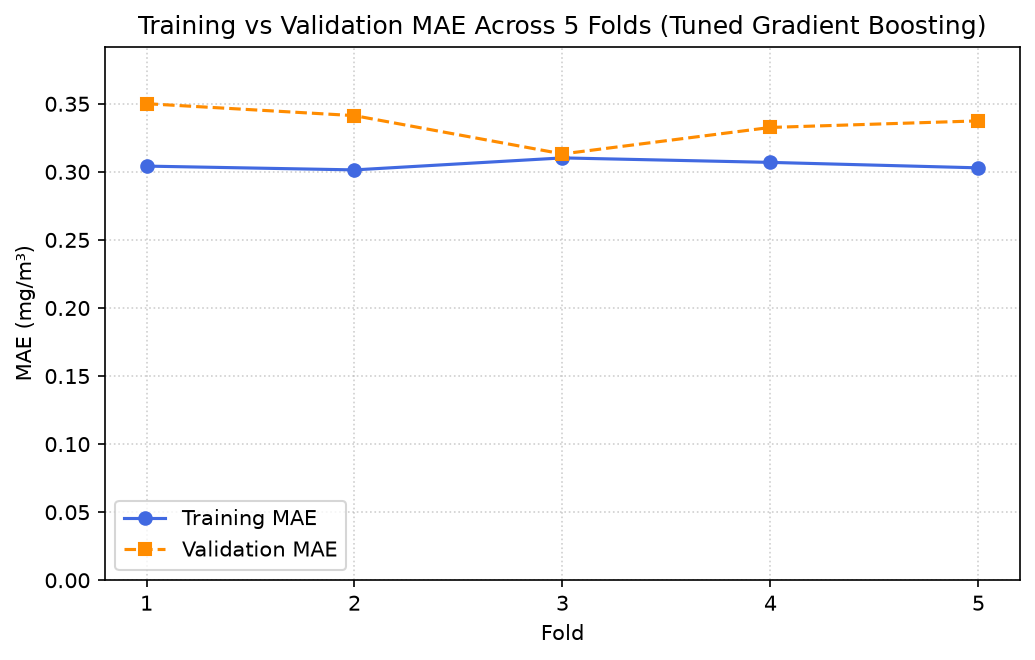

In [14]:
gb_fold_results = pd.DataFrame({
    'Fold': range(1, N_SPLITS + 1),
    'Training MAE': [
        -gb_results.loc[gb_best, f'split{i}_train_mae'] for i in range(N_SPLITS)
    ],
    'Validation MAE': [
        -gb_results.loc[gb_best, f'split{i}_test_mae'] for i in range(N_SPLITS)
    ]
})
display(gb_fold_results.round(4))

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)
ax.plot(gb_fold_results['Fold'], gb_fold_results['Training MAE'],
        'o-', color='royalblue', label='Training MAE')
ax.plot(gb_fold_results['Fold'], gb_fold_results['Validation MAE'],
        's--', color='darkorange', label='Validation MAE')
ax.set(title='Training vs Validation MAE Across 5 Folds (Tuned Gradient Boosting)',
       xlabel='Fold', ylabel='MAE (mg/m³)', xticks=range(1, N_SPLITS + 1))
ax.set_ylim(0, 1.12 * gb_fold_results[['Training MAE', 'Validation MAE']].to_numpy().max())
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
fig.tight_layout()
plt.show()


Selected features and feature importance


,Absolute training correlation,Selected in full development fit
pt08_s1_co,0.8806,True
pt08_s2_nmhc,0.9151,True
pt08_s3_nox,0.6990,True
pt08_s4_no2,0.6288,True
pt08_s5_o3,0.8538,True
temperature_c,0.0061,False
relative_humidity_pct,0.0658,False


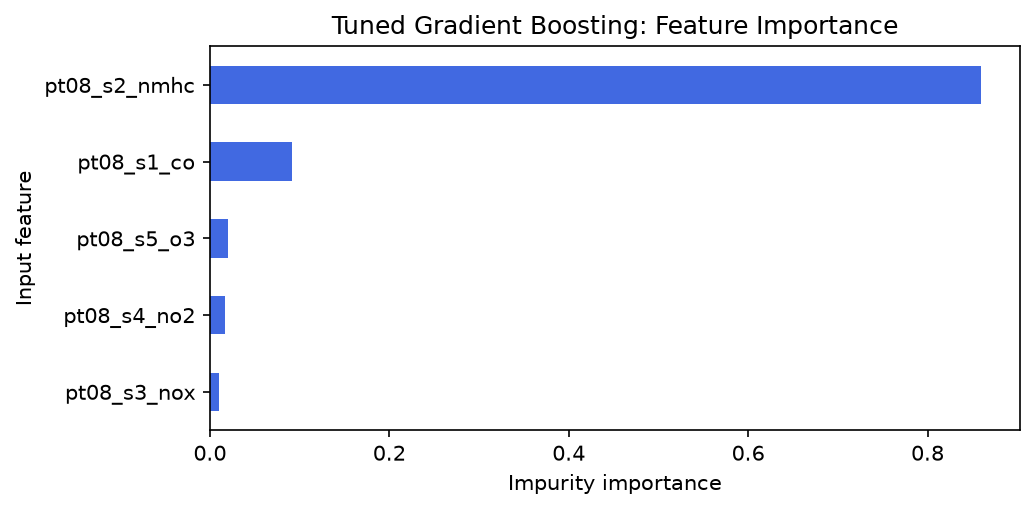

In [15]:
fitted_selector = gb_model.named_steps['prep'].named_steps['select']
selected_features = fitted_selector.get_feature_names_out().tolist()
feature_selection = fitted_selector.correlations_.rename('Absolute training correlation').to_frame()
feature_selection['Selected in full development fit'] = feature_selection.index.isin(selected_features)
display(feature_selection.round(4))

feature_importance = pd.Series(
    gb_model.named_steps['model'].feature_importances_,
    index=selected_features, name='Impurity importance'
).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5), dpi=150)
feature_importance.plot.barh(ax=ax, color='royalblue')
ax.set(xlabel='Impurity importance', ylabel='Input feature',
       title='Tuned Gradient Boosting: Feature Importance')
fig.tight_layout()
plt.show()


Benchmarking

Median of three timed runs after warm-up. Use the same CPU runtime for group comparisons. Memory is sampled incremental host RSS.


In [16]:
cost_results = {}
measure_host_memory = not RUNTIME_INFO['has_gpu']
if not measure_host_memory:
    print('Host-memory measurement skipped: select a CPU runtime to measure it.')

cost_table = ai4.ResultsTable()
for label, estimator in [
    ('Gradient boosting (default)', gb_pipe),
    ('Gradient boosting (tuned)', gb_model)
]:
    result = ai4.benchmark(
        estimator, X_train, y_train, X_test, y_test=None,
        repeats=BENCHMARK_REPEATS, label=label,
        measure_memory=measure_host_memory
    )
    cost_results[label] = result
    cost_table.add(label, result)

print('Benchmark runtime:', RUNTIME)
display(cost_table.df().rename(columns={
    'fit_s': 'Fit (s)', 'predict_s': 'Batch prediction (s)',
    'predict_ms_per_1k': 'Prediction (ms/1000 rows)',
    'peak_mem_mb': 'Incremental peak fit RSS (MiB)'
}).round(4))


Benchmark runtime: Windows | Intel64 Family 6 Model 183 Stepping 1, GenuineIntel (20 cores, 63.7 GB) | CPU only | Python 3.13.5


,model,score,Fit (s),Prediction (ms/1000 rows),fit_s_best,Batch prediction (s),n_train,n_test,repeats,Incremental peak fit RSS (MiB),mem_metric
0,Gradient boosting (default),None,0.6327,2.4758,0.6152,0.0038,6139,1535,3,0.0195,host process RSS (peak minus baseline)
1,Gradient boosting (tuned),None,1.8653,4.3330,1.8645,0.0067,6139,1535,3,0.1562,host process RSS (peak minus baseline)


Group comparison table


In [17]:
tuned_cost = cost_results['Gradient boosting (tuned)']
group_comparison = pd.DataFrame([{
    'Model': 'Gradient boosting (tuned)',
    'Training MAE (mg/m³)': float(gb_summary.iloc[0]['Training MAE']),
    'CV MAE (mg/m³)': float(gb_summary.iloc[0]['CV MAE']),
    'CV MAE SD (mg/m³)': float(gb_summary.iloc[0]['CV MAE SD']),
    'MAE gap (mg/m³)': float(gb_summary.iloc[0]['CV MAE'] - gb_summary.iloc[0]['Training MAE']),
    'CV R²': float(gb_summary.iloc[0]['CV R²']),
    'Fit (s)': tuned_cost['fit_s'],
    'Prediction (ms/1000 rows)': tuned_cost['predict_ms_per_1k'],
    'Incremental peak fit RSS (MiB)': tuned_cost.get('peak_mem_mb', np.nan)
}])
display(group_comparison.round(4))

protocol = {
    'Dataset period': DATA_PERIOD,
    'Labelled rows': len(df),
    'Development rows': len(X_train),
    'Held-out rows / inference batch rows': len(X_test),
    'Split': f'80/20 random; seed {SEED}',
    'CV': f'{N_SPLITS}-fold KFold; shuffle=True; seed {SEED}',
    'Feature rule': f'abs(Pearson r) >= {CORRELATION_THRESHOLD}; fitted inside each fold',
    'Full-development selected inputs': ', '.join(selected_features),
    'Imputation / scaling': 'Mean / StandardScaler; fitted inside each fold',
    'Selection metric': 'MAE (mg/m³)',
    'Dataset SHA-256': DATA_SHA256,
    'Runtime': RUNTIME,
    'scikit-learn': sklearn.__version__,
    'Search including refit (s)': round(gb_search_seconds, 4),
    'Selected settings': json.dumps(search_gb.best_params_, sort_keys=True)
}


,Model,Training MAE (mg/m³),CV MAE (mg/m³),CV MAE SD (mg/m³),MAE gap (mg/m³),CV R²,Fit (s),Prediction (ms/1000 rows),Incremental peak fit RSS (MiB)
0,Gradient boosting (tuned),0.3052,0.3349,0.0123,0.0298,0.8493,1.8653,4.333,0.1562


Final test (optional)

Enable `RUN_FINAL_TEST` after the group fixes its recommended model.


In [18]:
final_test_results = None
if RUN_FINAL_TEST:
    final_predictions = gb_model.predict(X_test)
    final_test_results = pd.DataFrame([{
        'Model': 'Gradient boosting (tuned)',
        'Test MAE (mg/m³)': mean_absolute_error(y_test, final_predictions),
        'Test RMSE (mg/m³)': np.sqrt(mean_squared_error(y_test, final_predictions)),
        'Test R²': r2_score(y_test, final_predictions),
        'Test rows': len(y_test)
    }])
    display(final_test_results.round(4))

    residuals = y_test.to_numpy() - final_predictions
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=150)
    axes[0].scatter(y_test, final_predictions, s=9, alpha=0.5, color='royalblue')
    low = min(y_test.min(), final_predictions.min())
    high = max(y_test.max(), final_predictions.max())
    axes[0].plot([low, high], [low, high], 'k--', linewidth=1)
    axes[0].set(xlabel='Actual CO (mg/m³)', ylabel='Predicted CO (mg/m³)',
                title='Held-out Predictions')
    axes[1].scatter(final_predictions, residuals, s=9, alpha=0.5, color='darkorange')
    axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
    axes[1].set(xlabel='Predicted CO (mg/m³)', ylabel='Actual − predicted (mg/m³)',
                title='Held-out Residuals')
    fig.tight_layout()
    plt.show()
else:
    print('Final test not evaluated. Use validation results for model selection.')


Final test not evaluated. Use validation results for model selection.


Notes

CV scores are used for tuning; earlier group work has already viewed the test split. Random folds assess same-period prediction.
